# Accidentes SAMUR Madrid, 2024: limpieza unificada y análisis

Este cuaderno junta en un solo sitio los dos procesos de limpieza que había en el repo y amplía el análisis visual:

| Origen | Qué aportaba |
| --- | --- |
| `1_2_severity/data_cleaning.ipynb` (caso 1.2) | normalización genérica de categorías (`norm_key` + grafía mayoritaria), `-1` → nulo en recuentos, relleno de huecos con cualquier columna del duplicado, registro de conflictos, `fecha_calendario` |
| `2_1_rag/pipeline.py` (caso 2.1) | fecha tomada del `numero_incidencia`, hora con ceros a la izquierda y segundos en `hora_decimal`, desempate por descripción más larga, `tipo_colision` inferido desde la descripción (caché en `.cache/`) |

Se aplica la **unión** de los dos métodos y se escribe un único CSV limpio común:

| Fuente | Ruta | Filas |
| --- | --- | --- |
| Bruto | `data/accidentes.csv` | 2 062 (100 incidencias duplicadas) |
| Limpio unificado | `data_clean/accidentes_clean.csv` | 1 962 (una fila por `numero_incidencia`) |

Las figuras se guardan en `data_viz/graficos_accidentes/`.

In [1]:
import json
import re
import unicodedata
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

HERE = Path.cwd()
ROOT = next(
    candidate
    for candidate in (HERE, HERE.parent, HERE / "data_viz")
    if (candidate / "data" / "accidentes.csv").exists()
)
VIZ = ROOT / "data_viz" / "graficos_accidentes"
VIZ.mkdir(exist_ok=True)

RAW_PATH = ROOT / "data" / "accidentes.csv"
OUT_PATH = ROOT / "data_clean" / "accidentes_clean.csv"
CACHE_PATH = ROOT / ".cache" / "tipo_colision.json"
RAG_CLEAN_PATH = ROOT / "data_clean" / "accidentes_clean-2.csv"  # CSV antiguo del caso 2.1; solo para comparar si existe

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.figsize": (9, 4.5),
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "savefig.dpi": 140,
    "savefig.bbox": "tight",
})
PALETTE = ["#1f4e79", "#c0392b", "#e67e22", "#1abc9c", "#7f8c8d", "#8e44ad"]


def savefig(name: str):
    path = VIZ / name
    plt.savefig(path)
    print(path.relative_to(ROOT))


def fmt(n) -> str:
    return f"{int(n):,}".replace(",", " ")


raw = pd.read_csv(RAW_PATH, dtype=object, keep_default_na=False)
print(f"raíz: {ROOT}")
print(f"bruto {raw.shape} ← {RAW_PATH.name}")

raíz: /Users/koss/Documents/Projects✅/Project-UC3M
bruto (2062, 21) ← accidentes.csv


## 1. Diagnóstico del CSV original

Antes de tocar nada se mide qué está mal. Se lee todo como texto para ver los valores tal y como vienen.

data_viz/graficos_accidentes/01_calidad_bruto.png


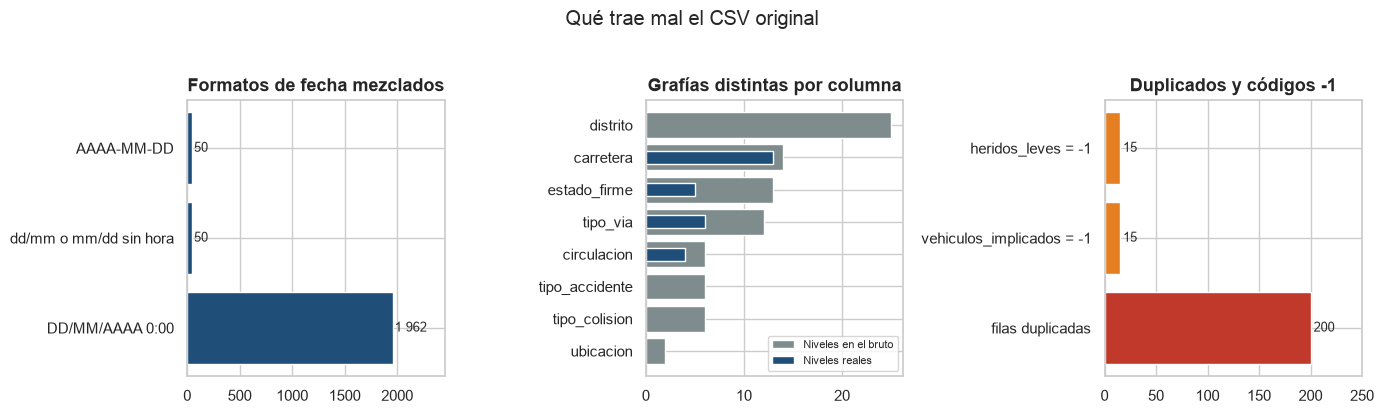


estado_firme: {'Seco y limpio': 1618, 'Mojado': 196, '(vacío)': 50, 'Seco': 40, 'SECO': 37, 'seco': 32, 'Otros': 32, 'SECO Y LIMPIO': 30, 'Húmedo': 9, 'MOJADO': 8, 'mojado': 6, '(En blanco)': 2, 'HUMEDO': 2}

tipo_via: {'TRONCO': 825, 'VIA DE SERVICIO': 685, 'RAMAL': 416, 'Ramal': 20, 'TRANSFER': 19, 'TABLERO': 17, 'Via de Servicio': 16, 'Transfer': 15, 'tronco': 14, 'Túnel': 12, 'TUNEL': 12, 'Tronco': 11}

circulacion: {'FLUIDA': 725, 'CONGESTIONADA': 646, 'DENSA': 599, '(vacío)': 75, '0': 12, '_': 5}

carretera: {'M30': 1705, 'A2': 103, 'M-607': 72, 'A5': 66, 'A4': 40, 'M11': 25, 'A3': 19, 'M500': 9, 'M23': 7, 'A1': 7, 'AV.ANDALUCIA': 3, 'A42': 3, 'M607': 2, '(vacío)': 1}


In [2]:
CAT_COLS = [
    "estado_firme", "tipo_via", "tipo_colision", "tipo_accidente",
    "ubicacion", "circulacion", "carretera", "distrito",
]
COUNT_COLS = [
    "vehiculos_implicados", "motos_implicadas", "pesados_implicados",
    "heridos_leves", "heridos_graves", "victimas_mortales",
]


def date_format(value: str) -> str:
    s = value.strip()
    if re.fullmatch(r"\d{4}-\d{2}-\d{2}", s):
        return "AAAA-MM-DD"
    if s.endswith(" 0:00"):
        return "DD/MM/AAAA 0:00"
    return "dd/mm o mm/dd sin hora"


formats = raw["fecha"].map(date_format).value_counts()
levels = raw[CAT_COLS].replace("", np.nan).nunique(dropna=False).sort_values()
minus_one = (raw[COUNT_COLS].apply(pd.to_numeric, errors="coerce") == -1).sum()
minus_one = minus_one[minus_one > 0]
dup_rows = int(raw["numero_incidencia"].duplicated(keep=False).sum())

fig, axes = plt.subplots(1, 3, figsize=(14, 4.0))
axes[0].barh(formats.index, formats.values, color=PALETTE[0])
axes[0].set_title("Formatos de fecha mezclados")
for y, v in enumerate(formats.values):
    axes[0].text(v + 15, y, fmt(v), va="center", fontsize=9)
axes[0].set_xlim(0, formats.max() * 1.25)

expected = {"estado_firme": 5, "tipo_via": 6, "circulacion": 4, "carretera": 13}
axes[1].barh(levels.index, levels.values, color=PALETTE[4], label="Niveles en el bruto")
axes[1].barh(list(expected), list(expected.values()), color=PALETTE[0], height=0.4, label="Niveles reales")
axes[1].set_title("Grafías distintas por columna")
axes[1].legend(loc="lower right", fontsize=8)

extra = pd.Series({"filas duplicadas": dup_rows, **{f"{k} = -1": v for k, v in minus_one.items()}})
axes[2].barh(extra.index, extra.values, color=[PALETTE[1]] + [PALETTE[2]] * (len(extra) - 1))
axes[2].set_title("Duplicados y códigos -1")
for y, v in enumerate(extra.values):
    axes[2].text(v + 3, y, fmt(v), va="center", fontsize=9)
axes[2].set_xlim(0, extra.max() * 1.25)
fig.suptitle("Qué trae mal el CSV original", y=1.03)
fig.tight_layout()
savefig("01_calidad_bruto.png")
plt.show()

for c in ["estado_firme", "tipo_via", "circulacion", "carretera"]:
    print(f"\n{c}: {raw[c].replace('', '(vacío)').value_counts().to_dict()}")

## 2. Limpieza unificada

Cada paso combina lo mejor de las dos versiones. Donde no coincidían se decide así:

| Paso | Caso 1.2 | Caso 2.1 | Unificado |
| --- | --- | --- | --- |
| Espacios y vacíos | – | `strip` y `""` → nulo | `strip` y `""` → nulo |
| Elegir fila del duplicado | más campos llenos (todas las columnas), luego la primera | más campos llenos (6 columnas), luego descripción más larga | más campos llenos (todas), luego descripción más larga, luego la primera |
| Rellenar huecos con la pareja | todas las columnas | 6 columnas | todas las columnas, y se registran los conflictos |
| Categorías | `norm_key` + mapa + grafía mayoritaria | mapas fijos por columna | `norm_key` + mapas fusionados (incluye `TABLERO` y `Otros`) |
| `carretera` | sin guion (`M607`) | con guion (`M-607`) | sin guion (`M607`), que es lo que usa `feature_engineering.ipynb` |
| Recuentos `-1` | → nulo | se quedaban en `-1` | → nulo |
| `fecha` | se conserva el texto; `fecha_calendario` se parsea probando formatos | fecha del `numero_incidencia` | `fecha` = fecha del `numero_incidencia` (AAAA-MM-DD); `fecha_calendario` igual, como `datetime` |
| `hora_decimal` | horas + minutos | horas + minutos + segundos | horas + minutos + segundos |
| `tipo_colision` vacío | se queda vacío | se infiere desde la descripción con Claude | se usa la caché de la inferencia; sin texto, vacío |
| Municipio | – | – | nuevo `fuera_de_madrid` (Móstoles, Alcorcón…) |

`LOG` guarda cuántas filas o celdas cambia cada paso para la figura del embudo.

In [3]:
JUNK = {"en blanco", "enblanco", "0", "", "nan", "none", "null", "na"}
LOG: list[tuple[str, int]] = []


def strip_accents(s: str) -> str:
    return "".join(c for c in unicodedata.normalize("NFKD", s) if not unicodedata.combining(c))


def norm_key(x) -> str | None:
    # Minúsculas, sin acentos ni signos. None para basura o nulo.
    if pd.isna(x):
        return None
    key = strip_accents(str(x).strip()).lower()
    key = re.sub(r"[^a-z0-9 ]", "", key)
    key = re.sub(r"\s+", " ", key).strip()
    return None if key in JUNK else key


def apply_map(series: pd.Series, mapping: dict) -> pd.Series:
    # Basura → nulo; claves del mapa → su etiqueta; el resto → grafía más frecuente.
    keys = series.map(norm_key)
    stripped = series.map(lambda v: str(v).strip())
    majority = {}
    for key, grp in stripped.groupby(keys, dropna=True):
        counts = grp.value_counts()
        majority[key] = sorted(counts[counts == counts.max()].index)[0]
    return keys.map(lambda k: np.nan if k is None or pd.isna(k) else mapping.get(k, majority[k])).astype("object")


def is_missing(v) -> bool:
    if pd.isna(v):
        return True
    s = str(v).strip()
    return s == "" or s == "-1"


df = raw.copy()
for c in df.columns:
    df[c] = df[c].str.strip()
df = df.replace("", np.nan)
snapshot_before = df[CAT_COLS].copy()
missing_before = df.isna().mean() * 100

### 2.1 Duplicados mutuos

100 `numero_incidencia` aparecen dos veces: misma hora y misma localización, es el mismo accidente escrito dos veces. Se conserva la fila más completa (desempate: descripción más larga, luego la primera). Los huecos de la fila conservada se rellenan con la otra copia y las discrepancias se anotan.

filas 2062 → 1962; celdas rellenadas: 3; conflictos: 45


numero_incidencia       columna                valor
    20240510-0027  estado_firme        Seco y limpio
    20240615-0007  estado_firme        Seco y limpio
    20241003-0020 tipo_colision COLISIÓN POR ALCANCE


data_viz/graficos_accidentes/02_conflictos_duplicados.png


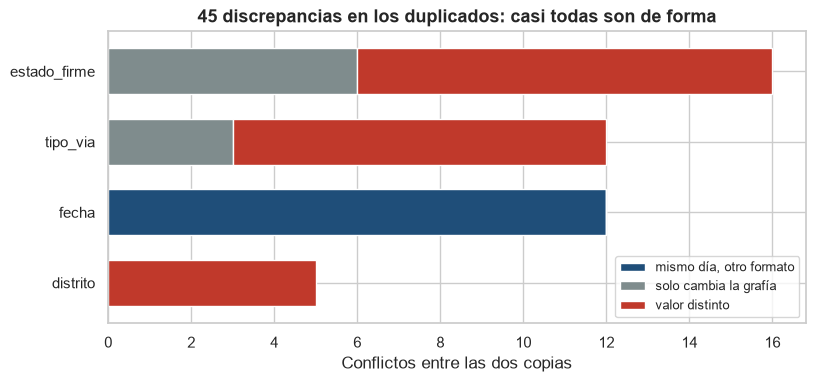

numero_incidencia      columna      conservado    descartado           tipo
    20240203-0004     distrito        ALCORCON         USERA valor distinto
    20240302-0019 estado_firme          Mojado        Húmedo valor distinto
    20240417-0017 estado_firme            SECO Seco y limpio valor distinto
    20240429-0037     distrito        MOSTOLES        RETIRO valor distinto
    20240510-0027     distrito      ALCOBENDAS       BARAJAS valor distinto
    20240607-0055     tipo_via        TRANSFER        TRONCO valor distinto
    20240607-0055 estado_firme            SECO Seco y limpio valor distinto
    20240612-0030     distrito        MOSTOLES       BARAJAS valor distinto
    20240617-0018 estado_firme   Seco y limpio          Seco valor distinto
    20240704-0024     tipo_via        TRANSFER        TRONCO valor distinto
    20240729-0038     tipo_via          TRONCO         RAMAL valor distinto
    20241009-0021 estado_firme          Mojado        HUMEDO valor distinto
    20241102

In [4]:
n_before = len(df)
keep_idx, conflicts, filled_from_dup = [], [], []

for nid, g in df.groupby("numero_incidencia", sort=False):
    if len(g) == 1:
        keep_idx.append(g.index[0])
        continue
    rank = pd.DataFrame({
        "filled": g.apply(lambda r: sum(not is_missing(v) for v in r), axis=1),
        "length": g["descripcion"].fillna("").str.len(),
        "order": -g.index.to_series(),
    })
    best = rank.sort_values(["filled", "length", "order"], ascending=False).index[0]
    keep_idx.append(best)
    for i, row in g.iterrows():
        if i == best:
            continue
        for col in g.columns:
            a, b = df.at[best, col], row[col]
            if is_missing(b):
                continue
            if is_missing(a):
                df.at[best, col] = b
                filled_from_dup.append((nid, col, b))
            elif str(a) != str(b):
                conflicts.append((nid, col, a, b))

df = df.loc[sorted(keep_idx)].reset_index(drop=True)
assert df["numero_incidencia"].is_unique
LOG.append(("Filas duplicadas eliminadas", n_before - len(df)))
LOG.append(("Celdas rellenadas con la pareja", len(filled_from_dup)))

conf = pd.DataFrame(conflicts, columns=["numero_incidencia", "columna", "conservado", "descartado"])
conf["tipo"] = np.where(
    conf.apply(lambda r: norm_key(r["conservado"]) == norm_key(r["descartado"]), axis=1),
    "solo cambia la grafía", "valor distinto",
)
conf.loc[conf["columna"] == "fecha", "tipo"] = "mismo día, otro formato"

print(f"filas {n_before} → {len(df)}; celdas rellenadas: {len(filled_from_dup)}; conflictos: {len(conf)}")
print(pd.DataFrame(filled_from_dup, columns=["numero_incidencia", "columna", "valor"]).to_string(index=False))

tab = conf.groupby(["columna", "tipo"]).size().unstack(fill_value=0)
tab = tab.loc[tab.sum(axis=1).sort_values().index]
fig, ax = plt.subplots(figsize=(9, 3.8))
tab.plot(kind="barh", stacked=True, ax=ax, width=0.65,
         color={"solo cambia la grafía": PALETTE[4], "mismo día, otro formato": PALETTE[0],
                "valor distinto": PALETTE[1]})
ax.set_xlabel("Conflictos entre las dos copias")
ax.set_ylabel("")
ax.set_title(f"{len(conf)} discrepancias en los duplicados: casi todas son de forma")
ax.legend(loc="lower right", fontsize=9)
savefig("02_conflictos_duplicados.png")
plt.show()
print(conf[conf["tipo"] == "valor distinto"].to_string(index=False))

### 2.2 Categorías, recuentos, fechas y hora

In [5]:
MAPS = {
    "estado_firme": {
        "seco y limpio": "Seco y limpio", "seco": "Seco y limpio",
        "mojado": "Mojado", "humedo": "Húmedo", "otros": "Otros",
    },
    "tipo_via": {
        "tronco": "TRONCO", "via de servicio": "VIA DE SERVICIO", "ramal": "RAMAL",
        "transfer": "TRANSFER", "tablero": "TABLERO", "tunel": "TUNEL",
    },
    "tipo_colision": {
        "colision por alcance": "COLISIÓN POR ALCANCE", "colision lateral": "COLISIÓN LATERAL",
        "colision frontal": "COLISIÓN FRONTAL", "colision mediana": "COLISIÓN MEDIANA", "otro": "Otro",
    },
}

changed_cats = 0
for col in CAT_COLS:
    before = df[col].copy()
    if col == "carretera":
        df[col] = df[col].map(lambda v: np.nan if norm_key(v) is None else str(v).strip().upper().replace("-", ""))
    else:
        df[col] = apply_map(df[col], MAPS.get(col, {}))
    changed_cats += int((before.fillna("∅") != df[col].fillna("∅")).sum())
LOG.append(("Celdas categóricas unificadas o vaciadas", changed_cats))

minus_one_total = 0
for c in COUNT_COLS:
    df[c] = pd.to_numeric(df[c], errors="coerce")
    minus_one_total += int((df[c] == -1).sum())
    df.loc[df[c] == -1, c] = np.nan
LOG.append(("Recuentos -1 pasados a nulo", minus_one_total))


def parse_fecha(val):
    # Lectura del texto original probando DMY, ISO y MDY (método del caso 1.2).
    if pd.isna(val):
        return pd.NaT
    s = str(val).split()[0]
    for f in ("%d/%m/%Y", "%Y-%m-%d", "%m/%d/%Y"):
        try:
            return pd.to_datetime(s, format=f)
        except ValueError:
            continue
    return pd.NaT


id_date = pd.to_datetime(df["numero_incidencia"].str.slice(0, 8), format="%Y%m%d")
text_date = df["fecha"].map(parse_fecha)
date_fixed = int((text_date != id_date).sum())
LOG.append(("Fechas corregidas con el numero_incidencia", date_fixed))
df["fecha"] = id_date.dt.strftime("%Y-%m-%d")
df["fecha_calendario"] = id_date

hora = pd.to_datetime(
    df["hora"].map(lambda v: "{:02d}:{:02d}:{:02d}".format(*map(int, str(v).split(":")))),
    format="%H:%M:%S",
)
df["hora"] = hora.dt.strftime("%H:%M:%S")
df["hora_decimal"] = (hora.dt.hour + hora.dt.minute / 60 + hora.dt.second / 3600).round(4)
df["unidad_samur_id"] = pd.to_numeric(df["unidad_samur_id"], errors="coerce").astype("Int64")
df["grave"] = ((df["heridos_graves"].fillna(0) > 0) | (df["victimas_mortales"].fillna(0) > 0)).astype(int)

print(f"categorías: {changed_cats} celdas cambiadas | -1 → nulo: {minus_one_total} | fechas corregidas: {date_fixed}")
print(f"grave = 1 en {df['grave'].sum()} de {len(df)} ({100 * df['grave'].mean():.2f}%)")
ex = pd.DataFrame({"texto": raw.loc[sorted(keep_idx), "fecha"].values, "leida": text_date.values, "id": id_date.values})
print("\nEjemplos donde el texto leído no coincide con el id:")
print(ex[ex["leida"] != ex["id"]].head(6).to_string(index=False))

categorías: 314 celdas cambiadas | -1 → nulo: 27 | fechas corregidas: 42
grave = 1 en 45 de 1962 (2.29%)

Ejemplos donde el texto leído no coincide con el id:
          texto      leida         id
     01/02/2024 2024-02-01 2024-01-02
     01/09/2024 2024-09-01 2024-01-09
     02/01/2024 2024-01-02 2024-02-01
     02/05/2024 2024-05-02 2024-02-05
     02/05/2024 2024-05-02 2024-02-05
13/03/2024 0:00 2024-03-13 2024-03-12


### 2.3 `tipo_colision` inferido y municipio

`2_1_rag/pipeline.py` clasificó con Claude los `tipo_colision` vacíos que tienen descripción y guardó el resultado en `.cache/tipo_colision.json`. Aquí se reutiliza esa caché (sin llamar a la API); si no está (`.cache/` no se sube al repositorio), se toman los tipos inferidos que ya guarda `data_clean/accidentes_clean.csv`. Solo se aplica cuando la descripción coincide con la que se clasificó.

`distrito` mezcla los 19 distritos de Madrid con municipios del área metropolitana. Se marca con `fuera_de_madrid`.

In [6]:
if CACHE_PATH.exists():
    cache = json.loads(CACHE_PATH.read_text())
    source = CACHE_PATH.relative_to(ROOT)
else:
    # Sin caché local (.cache/ no se versiona): se reutilizan los tipos inferidos
    # que ya guarda el CSV limpio del repositorio.
    rag = pd.read_csv(OUT_PATH)
    rag = rag[rag["tipo_colision_inferido"]]
    cache = {r.numero_incidencia: {"descripcion": r.descripcion, "tipo_colision": r.tipo_colision}
             for r in rag.itertuples()}
    source = OUT_PATH.relative_to(ROOT)

blank = df["tipo_colision"].isna()
df["tipo_colision_inferido"] = False
for i in df.index[blank & df["descripcion"].notna()]:
    hit = cache.get(df.at[i, "numero_incidencia"])
    if hit and hit["descripcion"] == df.at[i, "descripcion"]:
        df.at[i, "tipo_colision"] = MAPS["tipo_colision"].get(norm_key(hit["tipo_colision"]), np.nan)
        df.at[i, "tipo_colision_inferido"] = True
n_infer = int(df["tipo_colision_inferido"].sum())
LOG.append(("tipo_colision inferidos desde la descripción", n_infer))

MUNICIPIOS = {"MOSTOLES", "ALCORCON", "ALCOBENDAS", "LEGANES", "GETAFE", "SAN SEBASTIAN DE LOS REYES"}
df["fuera_de_madrid"] = df["distrito"].isin(MUNICIPIOS)

print(f"fuente de la inferencia: {source}")
print(f"tipo_colision vacíos tras deduplicar: {int(blank.sum())}; inferidos: {n_infer}; "
      f"siguen vacíos: {int(df['tipo_colision'].isna().sum())} "
      f"(sin descripción: {int((df['tipo_colision'].isna() & df['descripcion'].isna()).sum())})")
print(f"partes fuera del municipio de Madrid: {int(df['fuera_de_madrid'].sum())}")

fuente de la inferencia: .cache/tipo_colision.json
tipo_colision vacíos tras deduplicar: 71; inferidos: 68; siguen vacíos: 3 (sin descripción: 3)
partes fuera del municipio de Madrid: 50


### 2.4 Guardar y comprobar

In [7]:
ORDER = [
    "fecha", "hora", "numero_incidencia", "localizacion", "ubicacion", "carretera", "eje",
    "tipo_via", "tipo_accidente", "tipo_colision", *COUNT_COLS[:3], "estado_firme", "circulacion",
    *COUNT_COLS[3:], "descripcion", "distrito", "unidad_samur_id",
    "fecha_calendario", "hora_decimal", "grave", "tipo_colision_inferido", "fuera_de_madrid",
]
clean = df[ORDER].copy()
clean.to_csv(OUT_PATH, index=False)
print(f"escrito {OUT_PATH.relative_to(ROOT)} {clean.shape}")

report = pd.DataFrame({
    "niveles_antes": snapshot_before.nunique(dropna=False),
    "niveles_después": clean[CAT_COLS].nunique(dropna=False),
    "nulos_antes": snapshot_before.isna().sum(),
    "nulos_después": clean[CAT_COLS].isna().sum(),
})
print(report.to_string())

if RAG_CLEAN_PATH.exists():
    rag = pd.read_csv(RAG_CLEAN_PATH).set_index("numero_incidencia").loc[clean["numero_incidencia"]]
    cmp = clean.set_index("numero_incidencia")
    as_text = lambda s: s.astype(object).where(s.notna(), "∅").astype(str).str.strip()
    diff = {c: int((as_text(cmp[c]) != as_text(rag[c])).sum())
            for c in ["fecha", "hora", "tipo_colision", "estado_firme", "tipo_via", "circulacion",
                      "carretera", "grave", "descripcion"]}
    diff["vehiculos_implicados = -1 (solo en 2.1)"] = int((rag["vehiculos_implicados"] == -1).sum())
    diff["heridos_leves = -1 (solo en 2.1)"] = int((rag["heridos_leves"] == -1).sum())
    print("\nDiferencias con data_clean/accidentes_clean-2.csv (caso 2.1):")
    print(pd.Series(diff).to_string())
    print("carretera solo difiere por la grafía M607 / M-607.")

escrito data_clean/accidentes_clean.csv (1962, 26)
                niveles_antes  niveles_después  nulos_antes  nulos_después
estado_firme               13                5           50             48
tipo_via                   12                6            0              0
tipo_colision               6                6           80              3
tipo_accidente              6                6            0              0
ubicacion                   2                2            0              0
circulacion                 6                4           75             85
carretera                  14               13            1              1
distrito                   25               25            0              0

Diferencias con data_clean/accidentes_clean-2.csv (caso 2.1):
fecha                                       0
hora                                        0
tipo_colision                               0
estado_firme                                0
tipo_via                   

### 2.5 El proceso en una figura

data_viz/graficos_accidentes/03_pipeline_limpieza.png


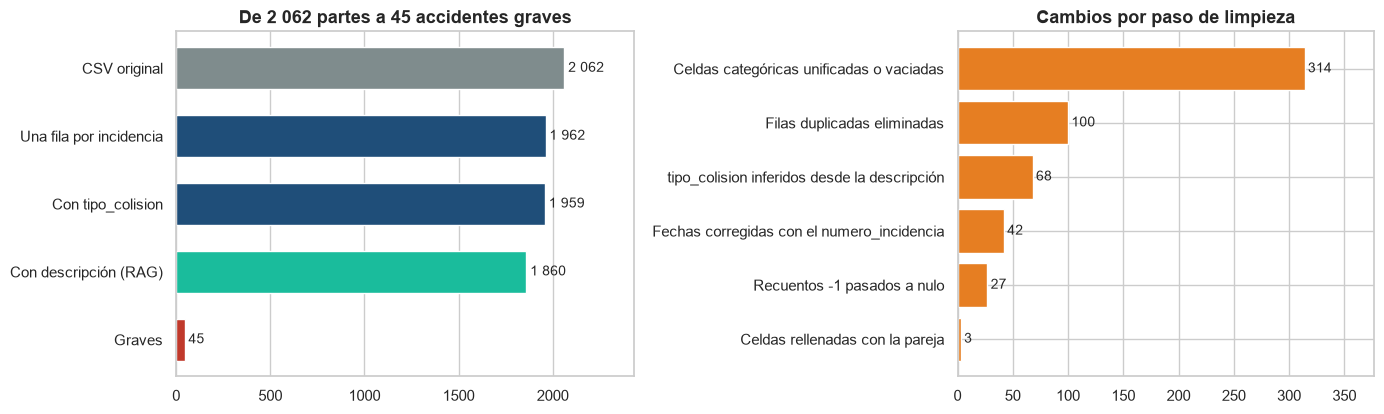

data_viz/graficos_accidentes/04_huecos_y_tipo_colision.png


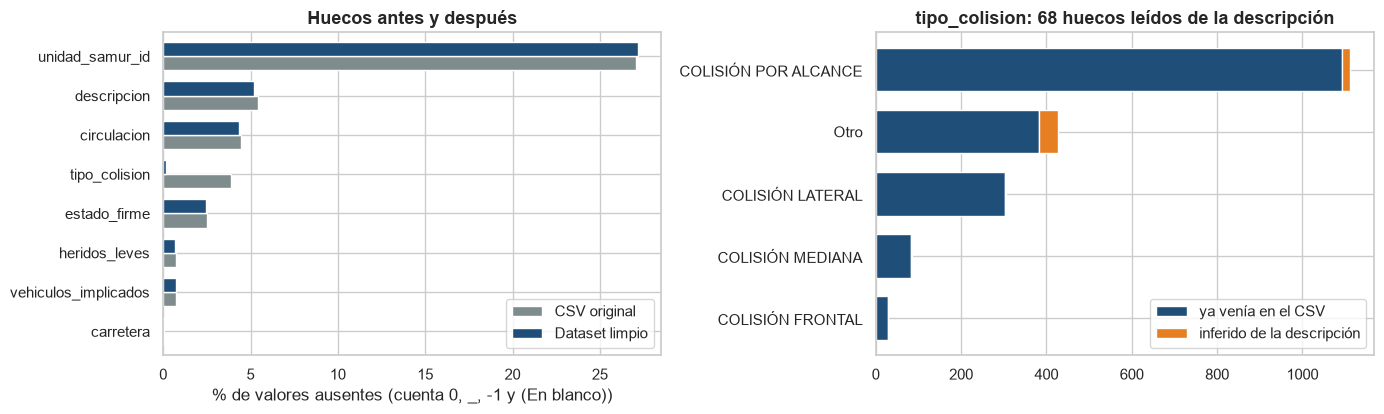

                      CSV original  Dataset limpio
carretera                     0.05            0.05
vehiculos_implicados          0.73            0.71
heridos_leves                 0.73            0.66
estado_firme                  2.52            2.45
tipo_colision                 3.88            0.15
circulacion                   4.46            4.33
descripcion                   5.43            5.20
unidad_samur_id              27.06           27.17


In [8]:
clean["con_moto"] = clean["motos_implicadas"].fillna(0).ge(1)
clean["con_pesado"] = clean["pesados_implicados"].fillna(0).ge(1)
clean["hora_int"] = clean["hora_decimal"].astype(int).clip(0, 23)
n_raw, n_clean, n_grave = len(raw), len(clean), int(clean["grave"].sum())
n_desc = int(clean["descripcion"].notna().sum())

fig, axes = plt.subplots(1, 2, figsize=(14, 4.3), gridspec_kw={"width_ratios": [1.1, 1]})
stages = [
    ("CSV original", n_raw),
    ("Una fila por incidencia", n_clean),
    ("Con tipo_colision", n_clean - int(clean["tipo_colision"].isna().sum())),
    ("Con descripción (RAG)", n_desc),
    ("Graves", n_grave),
]
labels, values = zip(*stages)
colors = [PALETTE[4], PALETTE[0], PALETTE[0], PALETTE[3], PALETTE[1]]
axes[0].barh(labels[::-1], values[::-1], color=colors[::-1], height=0.62)
for y, v in enumerate(values[::-1]):
    axes[0].text(v + 20, y, fmt(v), va="center", fontsize=10)
axes[0].set_xlim(0, n_raw * 1.18)
axes[0].set_title(f"De {fmt(n_raw)} partes a {n_grave} accidentes graves")
axes[0].grid(axis="y", visible=False)

log = pd.Series(dict(LOG)).sort_values()
axes[1].barh(log.index, log.values, color=PALETTE[2])
for y, v in enumerate(log.values):
    axes[1].text(v + 3, y, fmt(v), va="center", fontsize=10)
axes[1].set_xlim(0, log.max() * 1.2)
axes[1].set_title("Cambios por paso de limpieza")
fig.tight_layout()
savefig("03_pipeline_limpieza.png")
plt.show()

compare_cols = ["unidad_samur_id", "descripcion", "circulacion", "tipo_colision", "estado_firme",
                "vehiculos_implicados", "heridos_leves", "carretera"]
raw_na = raw[compare_cols].replace({"": np.nan, "-1": np.nan, "0": np.nan, "_": np.nan, "(En blanco)": np.nan})
raw_na["vehiculos_implicados"] = raw["vehiculos_implicados"].replace("-1", np.nan)
raw_na["heridos_leves"] = raw["heridos_leves"].replace("-1", np.nan)
missing = pd.DataFrame({
    "CSV original": raw_na.isna().mean() * 100,
    "Dataset limpio": clean[compare_cols].isna().mean() * 100,
}).sort_values("CSV original")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.3))
missing.plot(kind="barh", ax=axes[0], color=[PALETTE[4], PALETTE[0]], width=0.72)
axes[0].set_xlabel("% de valores ausentes (cuenta 0, _, -1 y (En blanco))")
axes[0].set_title("Huecos antes y después")
axes[0].legend(loc="lower right")

order = ["COLISIÓN POR ALCANCE", "Otro", "COLISIÓN LATERAL", "COLISIÓN MEDIANA", "COLISIÓN FRONTAL"]
mix = pd.DataFrame({
    "ya venía en el CSV": clean.loc[~clean["tipo_colision_inferido"], "tipo_colision"].value_counts(),
    "inferido de la descripción": clean.loc[clean["tipo_colision_inferido"], "tipo_colision"].value_counts(),
}).reindex(order[::-1]).fillna(0)
mix.plot(kind="barh", stacked=True, ax=axes[1], color=[PALETTE[0], PALETTE[2]], width=0.7)
axes[1].set_title(f"tipo_colision: {n_infer} huecos leídos de la descripción")
axes[1].set_ylabel("")
axes[1].legend(loc="lower right")
fig.tight_layout()
savefig("04_huecos_y_tipo_colision.png")
plt.show()
print(missing.round(2).to_string())

## 3. Cuándo ocurren

El dataset cubre **2024 entero**. El volumen sigue el tráfico laboral: menos partes en fin de semana, agosto a la mitad y dos picos diarios. La **gravedad no sigue el volumen**: de madrugada hay pocos partes, pero una fracción mayor acaba en herido grave o víctima mortal.

data_viz/graficos_accidentes/05_hora_volumen_gravedad.png


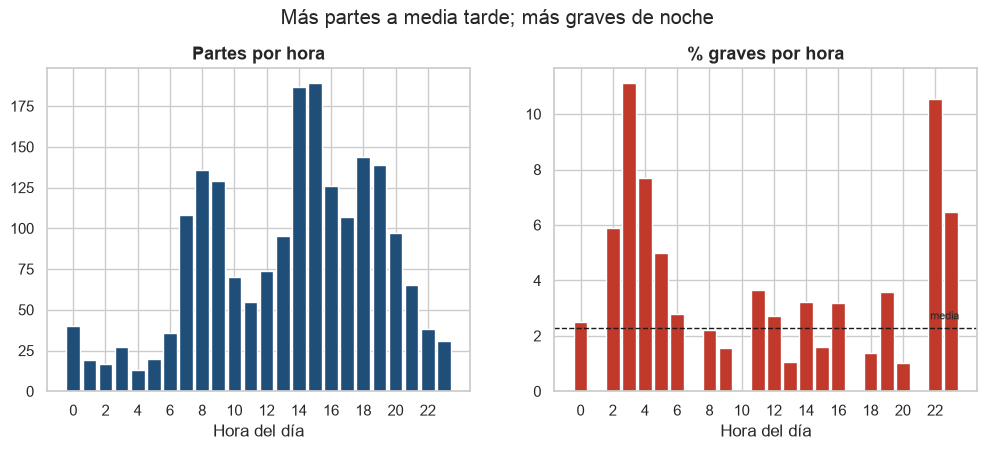

data_viz/graficos_accidentes/06_heatmap_dia_hora.png


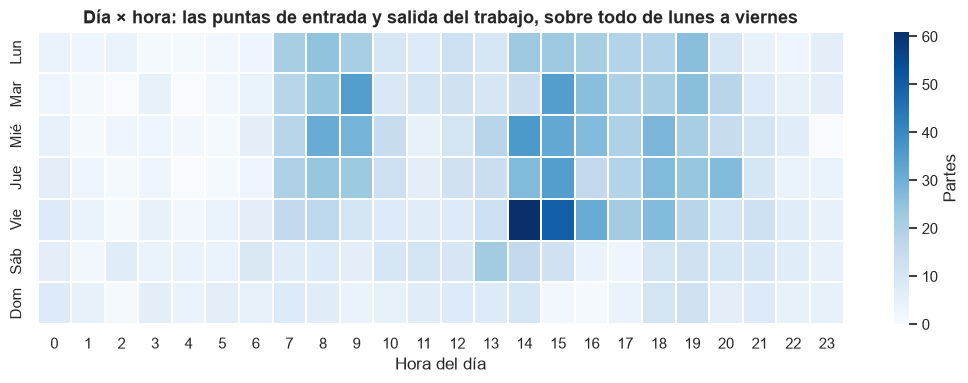

data_viz/graficos_accidentes/07_serie_mensual.png


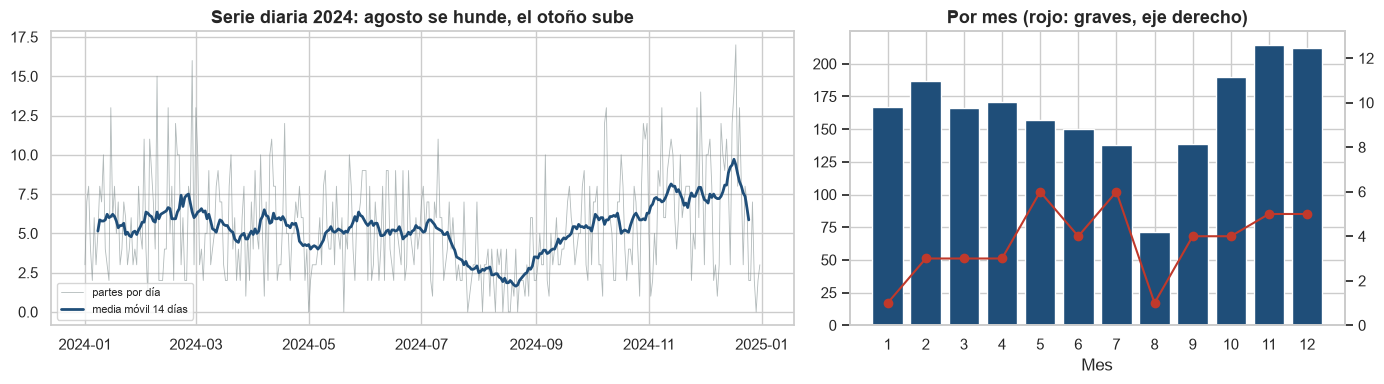

noche (22-5 h): 205 partes, 6.3% graves vs 1.8% de día
fin de semana: 346 partes (18%), 2.9% graves vs 2.2% laborable
media diaria 5.4; días sin partes: 10; máximo 17 (18-12)
fecha_calendario   1    2    3    4    5    6    7   8    9    10   11   12
n                 167  187  166  171  157  150  138  71  139  190  214  212
graves              1    3    3    3    6    4    6   1    4    4    5    5


In [9]:
by_hour = (
    clean.groupby("hora_int")["grave"]
    .agg(n="size", graves="sum", tasa="mean")
    .reindex(range(24), fill_value=0)
)
night = clean["hora_int"].isin([22, 23, 0, 1, 2, 3, 4, 5])

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
axes[0].bar(by_hour.index, by_hour["n"], color=PALETTE[0], width=0.85)
axes[0].set_title("Partes por hora")
axes[0].set_xlabel("Hora del día")
axes[0].set_xticks(range(0, 24, 2))
axes[1].bar(by_hour.index, 100 * by_hour["tasa"], color=PALETTE[1], width=0.85)
axes[1].axhline(100 * clean["grave"].mean(), color="k", lw=1, ls="--")
axes[1].text(23.5, 100 * clean["grave"].mean() + 0.3, "media", ha="right", fontsize=8)
axes[1].set_title("% graves por hora")
axes[1].set_xlabel("Hora del día")
axes[1].set_xticks(range(0, 24, 2))
fig.suptitle("Más partes a media tarde; más graves de noche", y=1.02)
savefig("05_hora_volumen_gravedad.png")
plt.show()

wd_es = ["Lun", "Mar", "Mié", "Jue", "Vie", "Sáb", "Dom"]
clean["dow"] = clean["fecha_calendario"].dt.day_of_week
heat = clean.pivot_table(index="dow", columns="hora_int", values="grave", aggfunc="size", fill_value=0)
heat = heat.reindex(index=range(7), columns=range(24), fill_value=0)
heat.index = wd_es

fig, ax = plt.subplots(figsize=(13, 3.8))
sns.heatmap(heat, cmap="Blues", ax=ax, cbar_kws={"label": "Partes"}, linewidths=0.3)
ax.set_xlabel("Hora del día")
ax.set_ylabel("")
ax.set_title("Día × hora: las puntas de entrada y salida del trabajo, sobre todo de lunes a viernes")
savefig("06_heatmap_dia_hora.png")
plt.show()

monthly = clean.groupby(clean["fecha_calendario"].dt.month)["grave"].agg(n="size", graves="sum")
daily = clean.groupby("fecha_calendario").size().reindex(pd.date_range("2024-01-01", "2024-12-31"), fill_value=0)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.0), gridspec_kw={"width_ratios": [1.5, 1]})
axes[0].plot(daily.index, daily.values, color=PALETTE[4], lw=0.6, alpha=0.6, label="partes por día")
axes[0].plot(daily.index, daily.rolling(14, center=True).mean(), color=PALETTE[0], lw=2, label="media móvil 14 días")
axes[0].set_title("Serie diaria 2024: agosto se hunde, el otoño sube")
axes[0].legend(loc="lower left", fontsize=8)
ax2 = axes[1]
ax2.bar(monthly.index, monthly["n"], color=PALETTE[0])
ax2.set_xticks(range(1, 13))
ax2.set_xlabel("Mes")
ax2.set_title("Por mes (rojo: graves, eje derecho)")
ax3 = ax2.twinx()
ax3.plot(monthly.index, monthly["graves"], color=PALETTE[1], marker="o")
ax3.set_ylim(0, monthly["graves"].max() * 2.2)
ax3.grid(False)
fig.tight_layout()
savefig("07_serie_mensual.png")
plt.show()

wk = clean["dow"] >= 5
print(f"noche (22-5 h): {night.sum()} partes, {100 * clean.loc[night, 'grave'].mean():.1f}% graves "
      f"vs {100 * clean.loc[~night, 'grave'].mean():.1f}% de día")
print(f"fin de semana: {fmt(wk.sum())} partes ({100 * wk.mean():.0f}%), "
      f"{100 * clean.loc[wk, 'grave'].mean():.1f}% graves vs {100 * clean.loc[~wk, 'grave'].mean():.1f}% laborable")
print(f"media diaria {daily.mean():.1f}; días sin partes: {int((daily == 0).sum())}; máximo {daily.max()} ({daily.idxmax():%d-%m})")
print(monthly.T.to_string())

## 4. Cómo y dónde

Esto no es una muestra de toda Madrid: **la gran mayoría de partes son en la M-30**. El resto se reparte en radiales (A-2, M-607, A-5…). Además, el campo `distrito` no cuadra con la carretera: hay partes de la M-30 en distritos por los que la M-30 no pasa.

data_viz/graficos_accidentes/08_tipo_colision_y_accidente.png


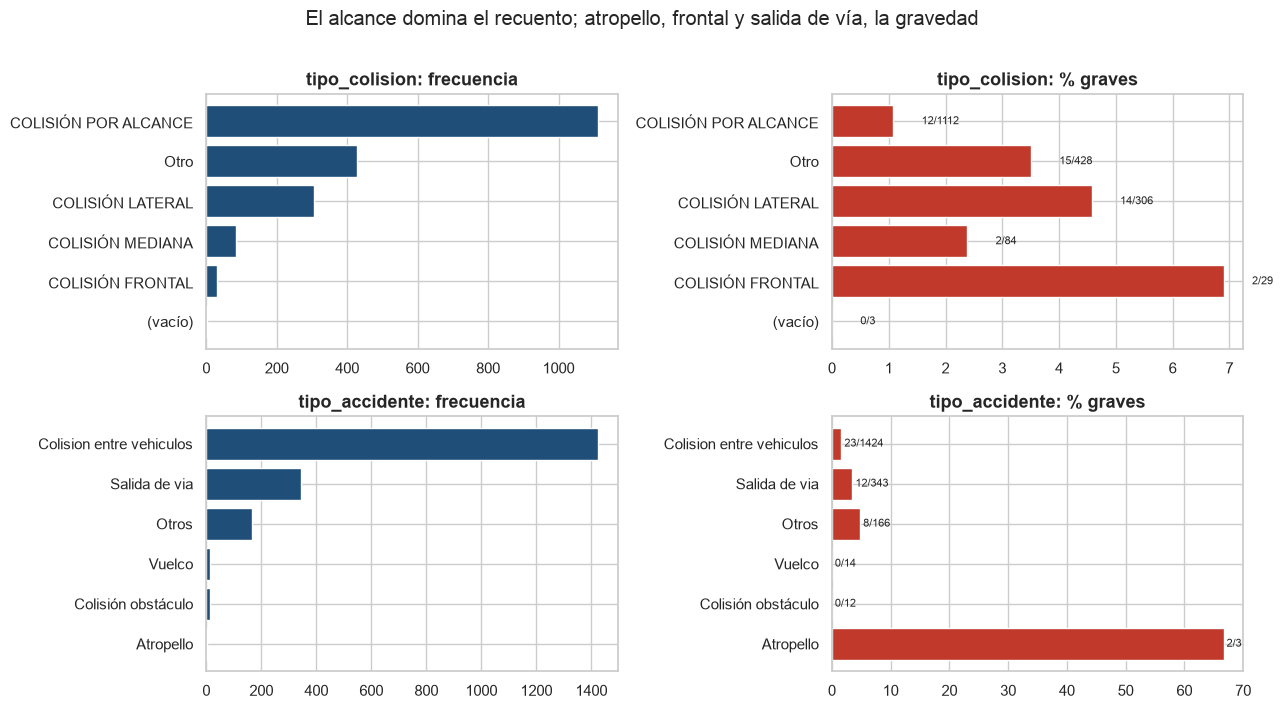

data_viz/graficos_accidentes/09_carreteras_y_via.png


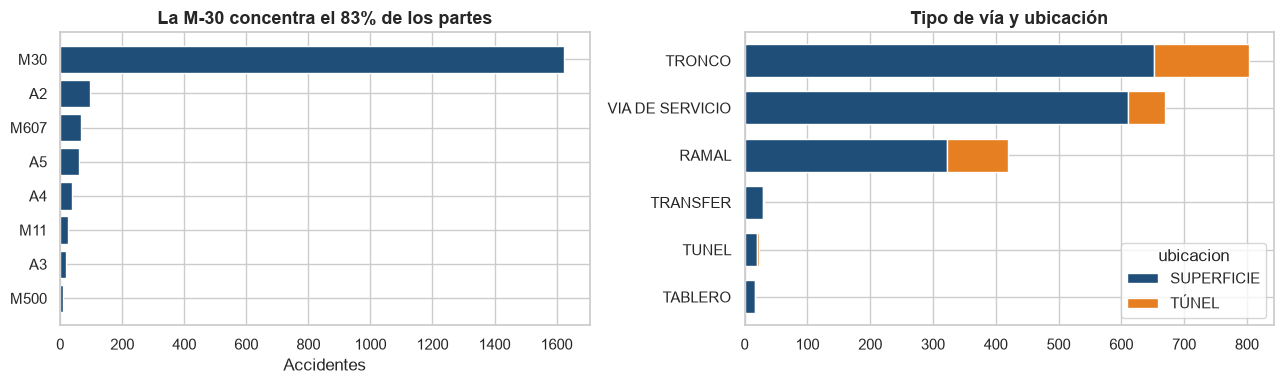

                         n  graves   tasa
tipo                                     
(vacío)                  3       0  0.000
COLISIÓN FRONTAL        29       2  0.069
COLISIÓN MEDIANA        84       2  0.024
COLISIÓN LATERAL       306      14  0.046
Otro                   428      15  0.035
COLISIÓN POR ALCANCE  1112      12  0.011

                             n  graves   tasa
tipo_accidente                               
Atropello                    3       2  0.667
Colisión obstáculo          12       0  0.000
Vuelco                      14       0  0.000
Otros                      166       8  0.048
Salida de via              343      12  0.035
Colision entre vehiculos  1424      23  0.016


In [10]:
col = (
    clean.assign(tipo=clean["tipo_colision"].fillna("(vacío)"))
    .groupby("tipo")["grave"].agg(n="size", graves="sum", tasa="mean")
    .sort_values("n")
)
acc = clean.groupby("tipo_accidente")["grave"].agg(n="size", graves="sum", tasa="mean").sort_values("n")

fig, axes = plt.subplots(2, 2, figsize=(13, 7))
for row, (table, name) in enumerate([(col, "tipo_colision"), (acc, "tipo_accidente")]):
    axes[row, 0].barh(table.index, table["n"], color=PALETTE[0])
    axes[row, 0].set_title(f"{name}: frecuencia")
    axes[row, 1].barh(table.index, 100 * table["tasa"], color=PALETTE[1])
    axes[row, 1].set_title(f"{name}: % graves")
    for y, (n, g, t) in enumerate(table[["n", "graves", "tasa"]].itertuples(index=False)):
        axes[row, 1].text(100 * t + 0.5, y, f"{int(g)}/{int(n)}", va="center", fontsize=8)
fig.suptitle("El alcance domina el recuento; atropello, frontal y salida de vía, la gravedad", y=1.01)
fig.tight_layout()
savefig("08_tipo_colision_y_accidente.png")
plt.show()

roads = clean["carretera"].fillna("(vacío)").value_counts().head(8).sort_values()
via = pd.crosstab(clean["tipo_via"], clean["ubicacion"])
via = via.loc[via.sum(axis=1).sort_values().index]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.0))
axes[0].barh(roads.index.astype(str), roads.values, color=PALETTE[0])
axes[0].set_title(f"La M-30 concentra el {100 * (clean['carretera'] == 'M30').mean():.0f}% de los partes")
axes[0].set_xlabel("Accidentes")
via.plot(kind="barh", stacked=True, ax=axes[1], color=[PALETTE[0], PALETTE[2]], width=0.7)
axes[1].set_title("Tipo de vía y ubicación")
axes[1].set_ylabel("")
fig.tight_layout()
savefig("09_carreteras_y_via.png")
plt.show()
print(col.round(3).to_string())
print()
print(acc.round(3).to_string())

data_viz/graficos_accidentes/10_distritos_coherencia.png


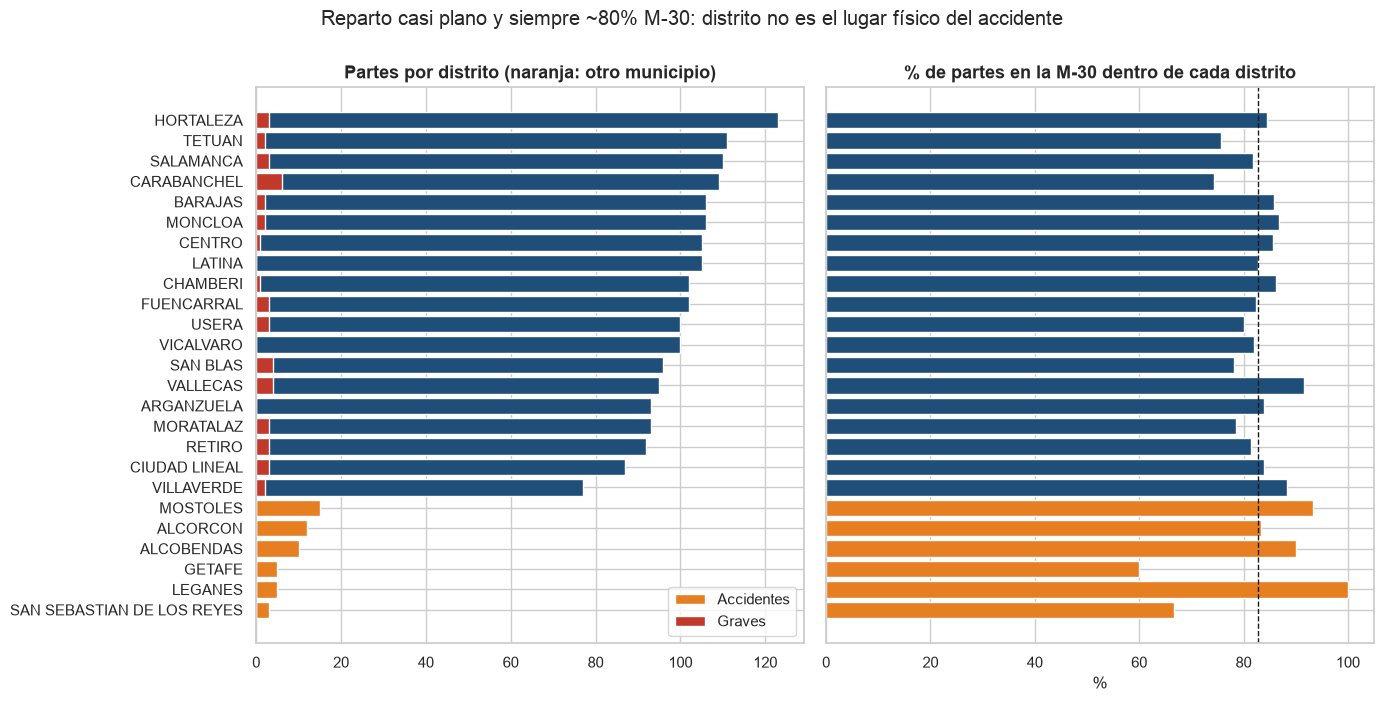

distritos de Madrid: 19; partes por distrito min 77, max 123, coef. variación 0.10
M-30 en Vicálvaro / Barajas (la M-30 no los cruza): 82 / 91
conflictos de distrito entre las dos copias del mismo parte: [['ALCORCON', 'USERA'], ['MOSTOLES', 'RETIRO'], ['ALCOBENDAS', 'BARAJAS'], ['MOSTOLES', 'BARAJAS'], ['GETAFE', 'MORATALAZ']]


In [11]:
dist = (
    clean.groupby("distrito")["grave"].agg(n="size", graves="sum", tasa="mean")
    .sort_values("n")
)
share_m30 = clean.groupby("distrito")["carretera"].apply(lambda s: (s == "M30").mean() * 100).reindex(dist.index)

fig, axes = plt.subplots(1, 2, figsize=(14, 7), sharey=True)
colors = [PALETTE[2] if d in MUNICIPIOS else PALETTE[0] for d in dist.index]
axes[0].barh(dist.index, dist["n"], color=colors, label="Accidentes")
axes[0].barh(dist.index, dist["graves"], color=PALETTE[1], label="Graves")
axes[0].set_title("Partes por distrito (naranja: otro municipio)")
axes[0].legend(loc="lower right")
axes[1].barh(dist.index, share_m30, color=colors)
axes[1].axvline(100 * (clean["carretera"] == "M30").mean(), color="k", ls="--", lw=1)
axes[1].set_title("% de partes en la M-30 dentro de cada distrito")
axes[1].set_xlabel("%")
fig.suptitle("Reparto casi plano y siempre ~80% M-30: distrito no es el lugar físico del accidente", y=1.0)
fig.tight_layout()
savefig("10_distritos_coherencia.png")
plt.show()

madrid = dist.loc[~dist.index.isin(MUNICIPIOS), "n"]
print(f"distritos de Madrid: {len(madrid)}; partes por distrito min {madrid.min()}, max {madrid.max()}, "
      f"coef. variación {madrid.std() / madrid.mean():.2f}")
print("M-30 en Vicálvaro / Barajas (la M-30 no los cruza):",
      int(((clean['distrito'] == 'VICALVARO') & (clean['carretera'] == 'M30')).sum()), "/",
      int(((clean['distrito'] == 'BARAJAS') & (clean['carretera'] == 'M30')).sum()))
print("conflictos de distrito entre las dos copias del mismo parte:",
      conf[conf["columna"] == "distrito"][["conservado", "descartado"]].values.tolist())

## 5. Qué se asocia a la gravedad

`grave` vale 1 si hay heridos graves o víctimas mortales: **45 casos (2,3 %)**. Con tan pocos positivos, una tasa calculada sobre 20 partes puede ser ruido. Por eso cada tasa va con su **intervalo de confianza al 95 % (Wilson)** y se compara con la media global. Solo se lee como señal lo que queda claramente separado de la media.

data_viz/graficos_accidentes/11_factores_gravedad_ic.png


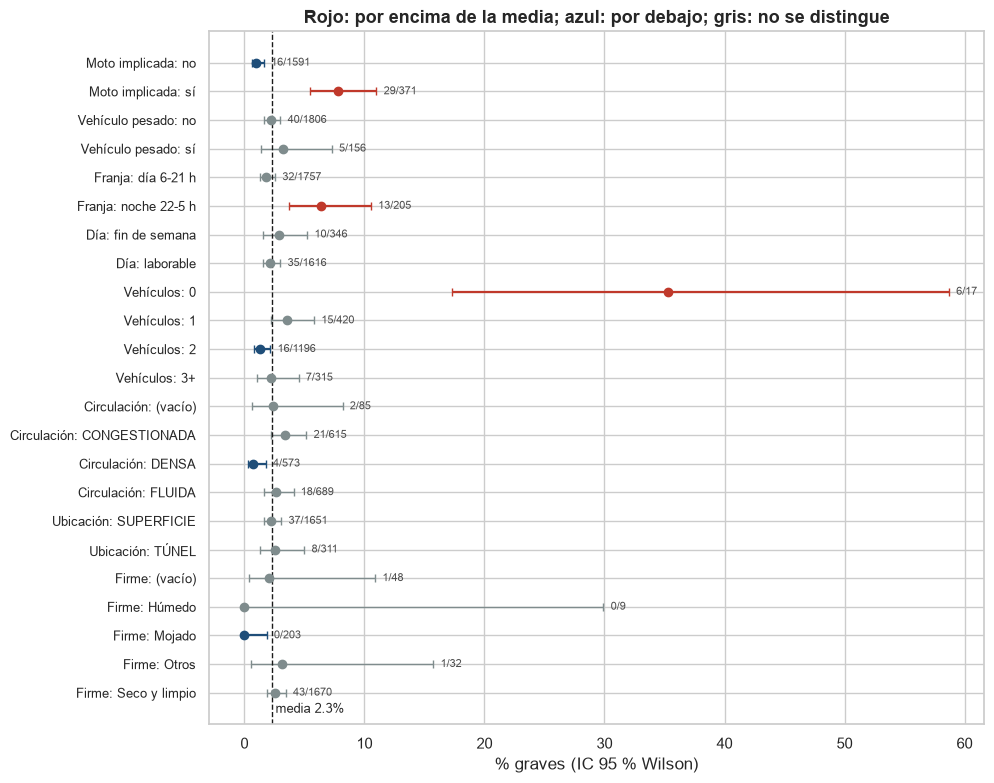

         factor         nivel    n  graves  tasa    lo    hi
 Moto implicada            no 1591      16  1.01  0.62  1.63
 Moto implicada            sí  371      29  7.82  5.50 11.00
Vehículo pesado            no 1806      40  2.21  1.63  3.00
Vehículo pesado            sí  156       5  3.21  1.38  7.28
         Franja    día 6-21 h 1757      32  1.82  1.29  2.56
         Franja  noche 22-5 h  205      13  6.34  3.74 10.55
            Día fin de semana  346      10  2.89  1.58  5.24
            Día     laborable 1616      35  2.17  1.56  3.00
      Vehículos             0   17       6 35.29 17.31 58.70
      Vehículos             1  420      15  3.57  2.18  5.81
      Vehículos             2 1196      16  1.34  0.83  2.16
      Vehículos            3+  315       7  2.22  1.08  4.52
    Circulación       (vacío)   85       2  2.35  0.65  8.18
    Circulación CONGESTIONADA  615      21  3.41  2.24  5.16
    Circulación         DENSA  573       4  0.70  0.27  1.78
    Circulación        F

In [12]:
def wilson(k, n, z=1.96):
    if n == 0:
        return np.nan, np.nan
    p = k / n
    den = 1 + z**2 / n
    centre = (p + z**2 / (2 * n)) / den
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / den
    return max(0.0, centre - half), min(1.0, centre + half)


veh = clean["vehiculos_implicados"]
factors = {
    "Moto implicada": np.where(clean["con_moto"], "sí", "no"),
    "Vehículo pesado": np.where(clean["con_pesado"], "sí", "no"),
    "Franja": np.where(night, "noche 22-5 h", "día 6-21 h"),
    "Día": np.where(clean["dow"] >= 5, "fin de semana", "laborable"),
    "Vehículos": pd.cut(veh, [-0.5, 0.5, 1.5, 2.5, 99], labels=["0", "1", "2", "3+"]).astype(str),
    "Circulación": clean["circulacion"].fillna("(vacío)"),
    "Ubicación": clean["ubicacion"],
    "Firme": clean["estado_firme"].fillna("(vacío)"),
}
rows = []
for factor, values in factors.items():
    g = clean.assign(v=values).groupby("v")["grave"].agg(["size", "sum"])
    for level, (n, k) in g.iterrows():
        if level == "nan":
            continue
        lo, hi = wilson(k, n)
        rows.append((factor, level, n, k, 100 * k / n, 100 * lo, 100 * hi))
risk = pd.DataFrame(rows, columns=["factor", "nivel", "n", "graves", "tasa", "lo", "hi"])
base = 100 * clean["grave"].mean()

fig, ax = plt.subplots(figsize=(10, 9))
labels = []
for y, r in enumerate(risk.itertuples()):
    signal = r.lo > base or r.hi < base
    color = PALETTE[1] if r.lo > base else (PALETTE[0] if r.hi < base else PALETTE[4])
    ax.errorbar(r.tasa, y, xerr=[[max(0, r.tasa - r.lo)], [max(0, r.hi - r.tasa)]], fmt="o", color=color,
                capsize=3, lw=1.6 if signal else 1)
    ax.text(max(r.hi, r.tasa) + 0.6, y, f"{int(r.graves)}/{int(r.n)}", va="center", fontsize=8, color="0.3")
    labels.append(f"{r.factor}: {r.nivel}")
ax.axvline(base, color="k", ls="--", lw=1)
ax.text(base + 0.3, len(risk) - 0.3, f"media {base:.1f}%", fontsize=9)
ax.set_yticks(range(len(labels)))
ax.set_yticklabels(labels, fontsize=9)
ax.invert_yaxis()
ax.set_xlabel("% graves (IC 95 % Wilson)")
ax.set_title("Rojo: por encima de la media; azul: por debajo; gris: no se distingue")
savefig("11_factores_gravedad_ic.png")
plt.show()
print(risk.round(2).to_string(index=False))

data_viz/graficos_accidentes/12_moto_por_hora.png


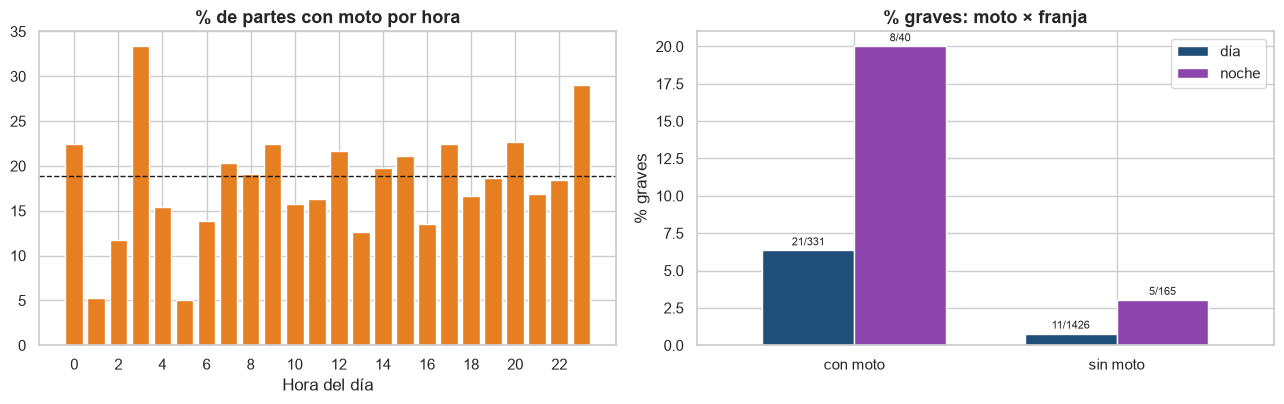

                   partes con ≥1  personas
heridos_leves                563       710
heridos_graves                40        41
victimas_mortales              7         7

partes sin ningún herido registrado: 1358 (69%)
                size  sum   mean
moto                            
con moto día     331   21  0.063
         noche    40    8  0.200
sin moto día    1426   11  0.008
         noche   165    5  0.030


In [13]:
moto = clean.assign(moto=np.where(clean["con_moto"], "con moto", "sin moto"))
cross = moto.groupby(["moto", np.where(night, "noche", "día")])["grave"].agg(["size", "sum", "mean"])
moto_hour = moto.groupby(["hora_int", "moto"]).size().unstack(fill_value=0)
moto_share = 100 * moto_hour["con moto"] / moto_hour.sum(axis=1)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
axes[0].bar(moto_share.index, moto_share.values, color=PALETTE[2])
axes[0].axhline(100 * clean["con_moto"].mean(), color="k", ls="--", lw=1)
axes[0].set_title("% de partes con moto por hora")
axes[0].set_xlabel("Hora del día")
axes[0].set_xticks(range(0, 24, 2))

cm = cross["mean"].unstack() * 100
cm.plot(kind="bar", ax=axes[1], color=[PALETTE[0], PALETTE[5]], rot=0, width=0.7)
for container, franja in zip(axes[1].containers, cm.columns):
    labels = [f"{int(cross.loc[(m, franja), 'sum'])}/{int(cross.loc[(m, franja), 'size'])}" for m in cm.index]
    axes[1].bar_label(container, labels=labels, fontsize=8, padding=2)
axes[1].set_title("% graves: moto × franja")
axes[1].set_xlabel("")
axes[1].set_ylabel("% graves")
axes[1].legend(title="")
fig.tight_layout()
savefig("12_moto_por_hora.png")
plt.show()

injury = clean[["heridos_leves", "heridos_graves", "victimas_mortales"]].fillna(0)
summary = pd.DataFrame({
    "partes con ≥1": (injury > 0).sum(),
    "personas": injury.sum().astype(int),
})
print(summary.to_string())
print(f"\npartes sin ningún herido registrado: {int((injury.sum(axis=1) == 0).sum())} "
      f"({100 * (injury.sum(axis=1) == 0).mean():.0f}%)")
print(cross.round(3).to_string())

data_viz/graficos_accidentes/13_correlaciones.png


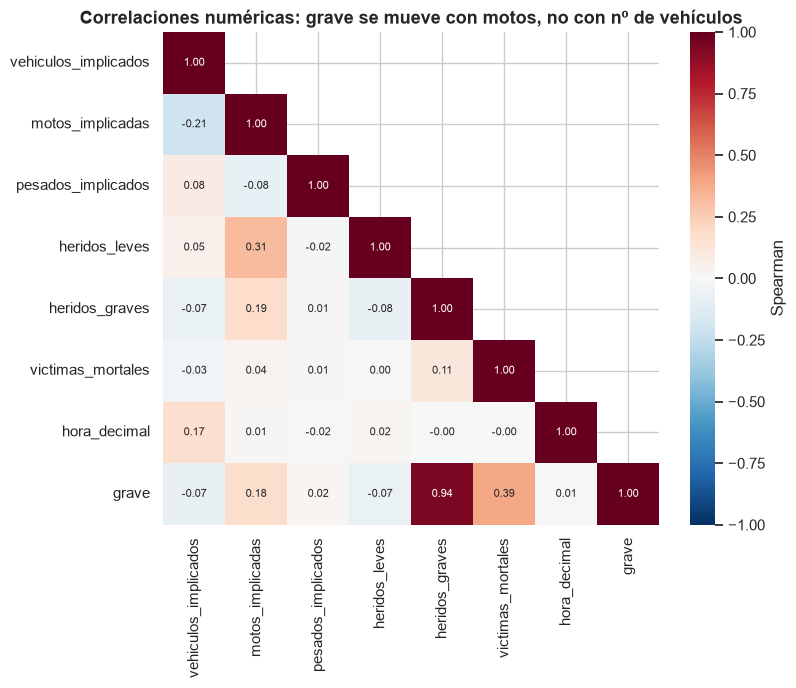

vehiculos_implicados   -0.071
heridos_leves          -0.067
hora_decimal            0.007
pesados_implicados      0.018
motos_implicadas        0.177
victimas_mortales       0.391
heridos_graves          0.942


In [14]:
corr_cols = ["vehiculos_implicados", "motos_implicadas", "pesados_implicados", "heridos_leves",
             "heridos_graves", "victimas_mortales", "hora_decimal", "grave"]
corr = clean[corr_cols].astype(float).corr(method="spearman")
fig, ax = plt.subplots(figsize=(8, 6.4))
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            ax=ax, cbar_kws={"label": "Spearman"}, annot_kws={"size": 8})
ax.set_title("Correlaciones numéricas: grave se mueve con motos, no con nº de vehículos")
savefig("13_correlaciones.png")
plt.show()
print(corr["grave"].drop("grave").sort_values().round(3).to_string())

## 6. Qué implica para el RAG

El agente busca **descripciones**, no recuentos. Los partes sin texto no entran en Pinecone. Los `tipo_colision` inferidos quedan en la tabla y se pueden usar como filtro, pero la búsqueda semántica solo ve lo escrito en `descripcion`. Comparar el vocabulario de los partes graves con el resto indica qué términos debería recuperar bien el retriever.

data_viz/graficos_accidentes/14_cobertura_descripcion.png


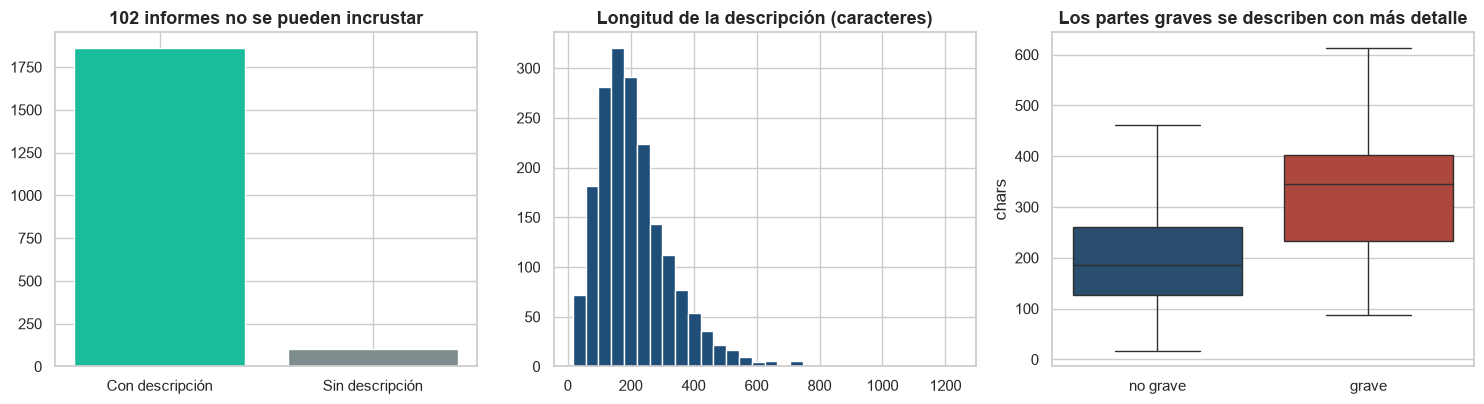

        count   mean    std   min    25%    50%    75%     max
grave                                                         
0      1816.0  209.0  117.0  16.0  127.0  186.0  261.0  1235.0
1        44.0  332.0  138.0  88.0  234.0  346.0  402.0   700.0

Sin descripción y graves: 1


In [15]:
clean["chars"] = clean["descripcion"].fillna("").str.len()
with_text = clean["descripcion"].notna()

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
axes[0].bar(["Con descripción", "Sin descripción"], [int(with_text.sum()), int((~with_text).sum())],
            color=[PALETTE[3], PALETTE[4]])
axes[0].set_title(f"{int((~with_text).sum())} informes no se pueden incrustar")
axes[1].hist(clean.loc[with_text, "chars"], bins=30, color=PALETTE[0], edgecolor="white")
axes[1].set_title("Longitud de la descripción (caracteres)")
sns.boxplot(data=clean[with_text], x="grave", y="chars", ax=axes[2],
            hue="grave", palette=[PALETTE[0], PALETTE[1]], legend=False, showfliers=False)
axes[2].set_xticks([0, 1], ["no grave", "grave"])
axes[2].set_xlabel("")
axes[2].set_title("Los partes graves se describen con más detalle")
fig.tight_layout()
savefig("14_cobertura_descripcion.png")
plt.show()
print(clean.loc[with_text].groupby("grave")["chars"].describe().round(0).to_string())
print("\nSin descripción y graves:", int((~with_text & clean["grave"].eq(1)).sum()))

data_viz/graficos_accidentes/15_vocabulario_graves.png


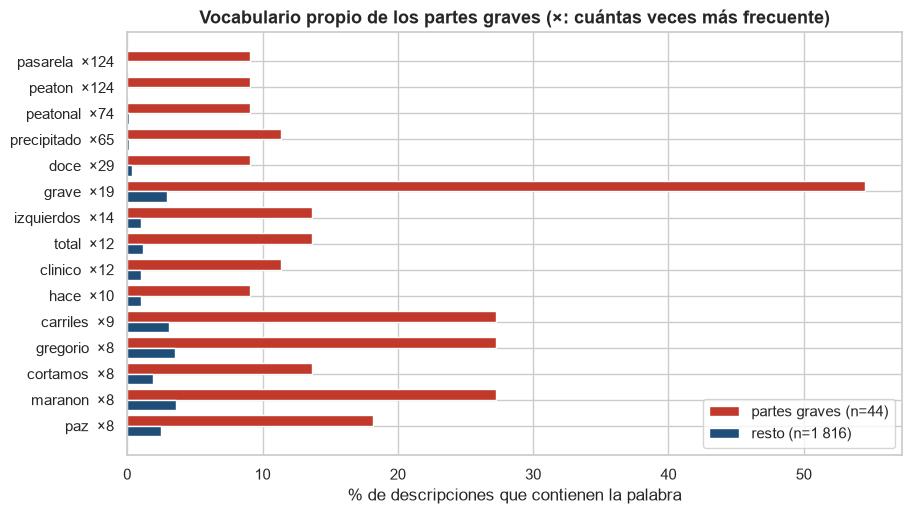

                g    ng  pct_g  pct_ng    lift
peaton        4.0   1.0   9.09    0.06  123.82
pasarela      4.0   1.0   9.09    0.06  123.82
peatonal      4.0   2.0   9.09    0.11   74.29
precipitado   5.0   3.0  11.36    0.17   64.86
doce          4.0   6.0   9.09    0.33   28.57
grave        24.0  54.0  54.55    2.97   18.55
izquierdos    6.0  19.0  13.64    1.05   13.76
total         6.0  21.0  13.64    1.16   12.48
clinico       5.0  18.0  11.36    0.99   12.27
hace          4.0  19.0   9.09    1.05    9.52
carriles     12.0  56.0  27.27    3.08    9.13
gregorio     12.0  64.0  27.27    3.52    8.00
cortamos      6.0  34.0  13.64    1.87    7.78
maranon      12.0  66.0  27.27    3.63    7.76
paz           8.0  45.0  18.18    2.48    7.71


In [16]:
STOP = set(
    "de la el en y a los del se las por con un una al que lo su para es no ha sin hay sobre como "
    "esta este son le o mas tras y/o cual sus muy ya entre desde".split()
)


def tokens(text: str) -> set[str]:
    words = re.findall(r"[a-zñ]{3,}", strip_accents(str(text)).lower())
    return {w for w in words if w not in STOP}


docs = clean.loc[with_text, ["descripcion", "grave"]].copy()
docs["tok"] = docs["descripcion"].map(tokens)
n_g, n_ng = int(docs["grave"].sum()), int((1 - docs["grave"]).sum())
df_g = pd.Series([w for t in docs.loc[docs["grave"] == 1, "tok"] for w in t]).value_counts()
df_ng = pd.Series([w for t in docs.loc[docs["grave"] == 0, "tok"] for w in t]).value_counts()
vocab = pd.DataFrame({"g": df_g, "ng": df_ng}).fillna(0)
vocab = vocab[vocab["g"] >= 4]
vocab["pct_g"] = 100 * vocab["g"] / n_g
vocab["pct_ng"] = 100 * vocab["ng"] / n_ng
vocab["lift"] = (vocab["g"] + 0.5) / n_g / ((vocab["ng"] + 0.5) / n_ng)
top = vocab.sort_values("lift", ascending=False).head(15).sort_values("lift")

fig, ax = plt.subplots(figsize=(10, 5.5))
y = np.arange(len(top))
ax.barh(y + 0.2, top["pct_g"], height=0.4, color=PALETTE[1], label=f"partes graves (n={n_g})")
ax.barh(y - 0.2, top["pct_ng"], height=0.4, color=PALETTE[0], label=f"resto (n={fmt(n_ng)})")
ax.set_yticks(y, [f"{w}  ×{l:.0f}" for w, l in zip(top.index, top["lift"])])
ax.set_xlabel("% de descripciones que contienen la palabra")
ax.set_title("Vocabulario propio de los partes graves (×: cuántas veces más frecuente)")
ax.legend(loc="lower right")
savefig("15_vocabulario_graves.png")
plt.show()
print(top.sort_values("lift", ascending=False).round(2).to_string())

data_viz/graficos_accidentes/16_texto_vs_etiqueta.png


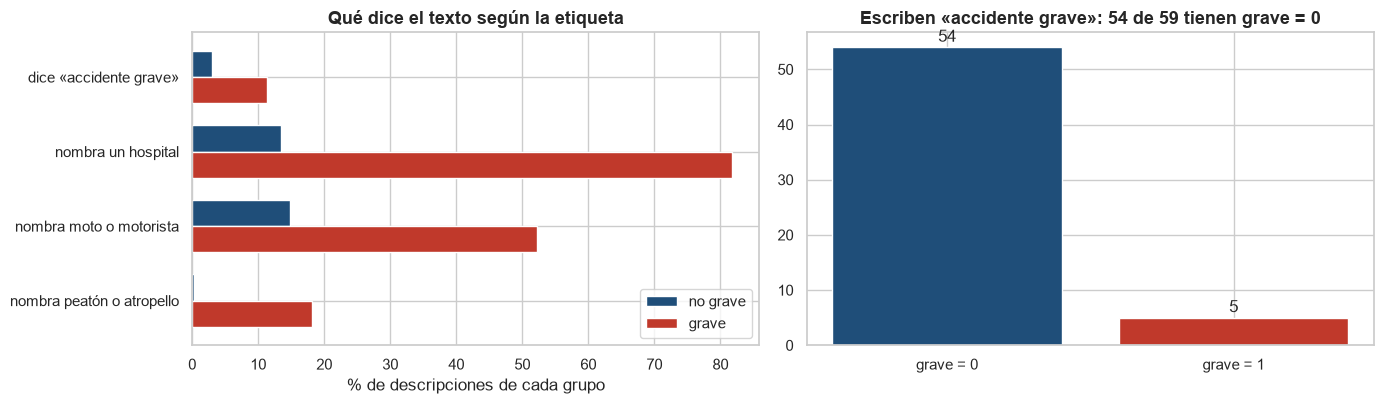

                           no grave  grave
dice «accidente grave»           54      5
nombra un hospital              243     36
nombra moto o motorista         270     23
nombra peatón o atropello         5      8

                           no grave  grave
dice «accidente grave»          3.0   11.4
nombra un hospital             13.4   81.8
nombra moto o motorista        14.9   52.3
nombra peatón o atropello       0.3   18.2


In [17]:
HOSP = r"DOCE|12 DE OCTUBRE|MARA[NÑ]ON|CL[IÍ]NICO|LA PAZ|RAM[OÓ]N Y CAJAL|PRINCESA|HOSPITAL"
text = clean.loc[with_text, ["descripcion", "grave"]]
flags = pd.DataFrame({
    "dice «accidente grave»": text["descripcion"].str.contains(r"ACCIDENTE GRAVE", case=False),
    "nombra un hospital": text["descripcion"].str.contains(HOSP, case=False),
    "nombra moto o motorista": text["descripcion"].str.contains(r"MOTO", case=False),
    "nombra peatón o atropello": text["descripcion"].str.contains(r"PEAT[OÓ]N|ATROPEL", case=False),
})
counts = flags.groupby(text["grave"]).sum().T
counts.columns = ["no grave", "grave"]
share = 100 * flags.groupby(text["grave"]).mean().T
share.columns = ["no grave", "grave"]

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
share.plot(kind="barh", ax=axes[0], color=[PALETTE[0], PALETTE[1]], width=0.7)
axes[0].set_xlabel("% de descripciones de cada grupo")
axes[0].set_title("Qué dice el texto según la etiqueta")
axes[0].legend(loc="lower right")
axes[0].invert_yaxis()
said = counts.loc["dice «accidente grave»"]
axes[1].bar(["grave = 0", "grave = 1"], said.values, color=[PALETTE[0], PALETTE[1]])
for x, v in enumerate(said.values):
    axes[1].text(x, v + 1, fmt(v), ha="center")
axes[1].set_title("Escriben «accidente grave»: 54 de 59 tienen grave = 0")
fig.tight_layout()
savefig("16_texto_vs_etiqueta.png")
plt.show()
print(counts.to_string())
print()
print(share.round(1).to_string())

## 7. Lectura corta

Los números exactos salen en las celdas de arriba; esto es el resumen.

1. **Limpieza unificada.** Un solo CSV, `data_clean/accidentes_clean.csv` (1 962 × 26), junta los métodos de los casos 1.2 y 2.1. Elimina 100 duplicados mutuos, rellena 3 celdas con la otra copia y registra 45 conflictos, casi todos de grafía o de formato de fecha. Unifica 314 celdas categóricas y pasa a nulo 27 recuentos `-1`, que el CSV del caso 2.1 dejaba en `-1`. Corrige 42 fechas con el `numero_incidencia`, infiere 68 `tipo_colision` desde la descripción y añade la marca `fuera_de_madrid` (50 partes).
2. **Volumen.** Unos 5,4 partes al día: laborables, M-30 (83 %) y horas punta de entrada y salida del trabajo. Agosto cae a 71 partes, menos de la mitad que noviembre (214). No es un censo de accidentes de Madrid: es el recorte SAMUR de estas vías.
3. **Distrito poco fiable como lugar.** Los 19 distritos de Madrid tienen entre 77 y 123 partes (coeficiente de variación 0,10), y en todos ~80 % son de la M-30, incluso en Vicálvaro (82) o Barajas (91), por donde la M-30 no pasa. En 5 duplicados la misma incidencia aparece con un distrito de Madrid y un municipio vecino. `distrito` no sirve como ubicación física del accidente sin validarlo con Bluetab.
4. **Gravedad.** Es una clase rara: 45 de 1 962 (2,3 %). Con IC al 95 % las señales robustas son **moto** (7,8 % frente a 1,0 %), **noche 22–5 h** (6,3 % frente a 1,8 %) y **0 vehículos**, que en la práctica son atropellos y caídas (6 de 17). Moto de noche llega al 20 % (8 de 40). La circulación densa (0,7 %) y el alcance (1,1 %) quedan por debajo de la media. Firme mojado, túnel, pesados o fin de semana no se distinguen de la media.
5. **Texto y RAG.** Hay 1 860 descripciones indexables y 102 partes sin texto (solo 1 grave). Los partes graves tienen el doble de texto (mediana 346 frente a 186 caracteres). El 82 % de los graves con texto (36 de 44) nombra un hospital (12 de Octubre, Gregorio Marañón, Clínico, La Paz), frente al 13 % del resto, y el 52 % nombra una moto. **«Accidente grave» en el texto no equivale a `grave = 1`**: 54 partes lo escriben con `grave = 0` y solo 5 con `grave = 1`. El texto refleja la alarma inicial del operario y la etiqueta, la lesividad final. Por eso el agente debe filtrar por el metadato `grave` y no fiarse de la búsqueda semántica para esa pregunta.

Figuras escritas en `data_viz/graficos_accidentes/` (`01_…` a `16_…`).